# EDA báo cáo cuối kỳ · Trọ Giá

**Ba câu hỏi để trình bày**  
1. Làm sạch đã thay đổi phân phối giá và diện tích thế nào?  
2. Các tiện ích trích xuất từ văn bản có phân tách được nhóm giá không?  
3. Trên tập test, đặc trưng nào đóng góp lớn nhất vào dự đoán của CatBoost?

Notebook chỉ đọc CSV và mô hình đã lưu. Chạy **Run All** từ thư mục dự án hoặc thư mục `src`. Nếu thiếu SHAP, cài trong môi trường kernel bằng `%pip install shap`.

In [1]:
import os
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    import shap
from catboost import Pool
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
set_matplotlib_formats("retina")

ROOT = os.getcwd()
if os.path.basename(ROOT) == "src":
    ROOT = os.path.dirname(ROOT)
SRC = os.path.join(ROOT, "src")
if SRC not in sys.path:
    sys.path.insert(0, SRC)
sys.dont_write_bytecode = True

# Tái sử dụng bộ đọc số của dự án. Hàm này chỉ phân tích chuỗi, không chạy pipeline.
from data_clean import MAX_AREA, MAX_RENT, MIN_RENT, parse_number

RAW, CLEAN = "#C6684A", "#187966"
TEXT_COLOR, MUTED_COLOR, GRID_COLOR = "#17362F", "#4D675E", "#DCE7E1"
sns.set_theme(style="whitegrid", context="notebook", rc={
    "font.family": ["Segoe UI", "DejaVu Sans"], "figure.dpi": 150,
    "savefig.dpi": 300, "text.color": TEXT_COLOR, "axes.labelcolor": TEXT_COLOR,
    "xtick.color": MUTED_COLOR, "ytick.color": MUTED_COLOR, "grid.color": GRID_COLOR,
    "axes.spines.top": False, "axes.spines.right": False,
})

def format_number(value, decimals=0):
    return f"{value:,.{decimals}f}".translate(str.maketrans(",.", ".,"))

## 1. Trước và sau làm sạch

Hai histogram của mỗi biến dùng cùng bin, thang trục và tỷ lệ phần trăm trên toàn bộ số giá trị dương đọc được của từng tập. Histogram tập trung vào **giá đến 12 triệu đồng/tháng** và **diện tích đến 120 m²**. Số điểm nằm ngoài khung được ghi dưới mỗi biểu đồ.

Boxplot bên phải giữ toàn bộ giá trị dương trên trục log. Hàng Raw loại các bản ghi bổ sung dùng để khôi phục thông tin (`recovery_note`) để so với tập tin thô ban đầu. Giá trị không đọc được, thiếu hoặc không dương được đếm riêng.

In [2]:
raw_all = pd.read_csv(os.path.join(ROOT, "data", "data_raw.csv"), dtype=str, low_memory=False)
clean = pd.read_csv(os.path.join(ROOT, "data", "data_clean.csv"))
supplemental_rows = raw_all["recovery_note"].fillna("").str.strip().ne("")
raw = raw_all.loc[~supplemental_rows]

NUMERIC_FIELDS = ("price", "area")
raw_numeric = pd.DataFrame({column: raw[column].map(lambda value_text: parse_number(value_text, column)) for column in NUMERIC_FIELDS})
clean_numeric = clean[list(NUMERIC_FIELDS)].apply(pd.to_numeric, errors="coerce")

def summarize_numeric(df, label):
    rows = []
    for column, name in zip(NUMERIC_FIELDS, ["Giá", "Diện tích"]):
        x = df[column]
        positive_values = x[x.gt(0)]
        outside_threshold = (
            (positive_values.lt(MIN_RENT) | positive_values.gt(MAX_RENT)) if column == "price"
            else positive_values.gt(MAX_AREA)
        )
        divisor = 1e6 if column == "price" else 1
        rows.append({
            "Biến": name, "Tập": label, "Số dòng": len(x),
            "Thiếu / không đọc được": int(x.isna().sum()), "Không dương": int(x.le(0).sum()),
            "Số dương ngoài ngưỡng": int(outside_threshold.sum()),
            "Trung vị": positive_values.median() / divisor, "P99": positive_values.quantile(.99) / divisor,
            "Lớn nhất": positive_values.max() / divisor,
        })
    return rows

audit = pd.DataFrame(summarize_numeric(raw_numeric, "Raw") + summarize_numeric(clean_numeric, "Clean"))
display(Markdown(f"**Quy mô** · {format_number(len(raw_all))} dòng trong file Raw, trong đó "
                 f"{format_number(supplemental_rows.sum())} dòng bổ sung. Biểu đồ đối chiếu "
                 f"{format_number(len(raw))} tin Raw ban đầu với {format_number(len(clean))} tin Clean."))
display(audit.set_index(["Biến", "Tập"]).style.format({
    "Trung vị": "{:,.2f}", "P99": "{:,.2f}", "Lớn nhất": "{:,.2f}",
}))
display(Markdown("Giá trong bảng dùng triệu đồng/tháng. Diện tích dùng m². "
                 "Ngưỡng nghiệp vụ là 0,3–30 triệu đồng/tháng và diện tích tối đa 200 m²."))

**Quy mô** · 16.740 dòng trong file Raw, trong đó 2.405 dòng bổ sung. Biểu đồ đối chiếu 14.335 tin Raw ban đầu với 8.037 tin Clean.

,,Số dòng,Thiếu / không đọc được,Không dương,Số dương ngoài ngưỡng,Trung vị,P99,Lớn nhất
Biến,Tập,,,,,,,
Giá,Raw,14335,684,49,139,2.80,11.00,"650,000.00"
Diện tích,Raw,14335,28,4,23,25.00,100.00,"1,000,000.00"
Giá,Clean,8037,0,0,0,2.50,6.03,28.00
Diện tích,Clean,8037,10,0,0,20.00,55.00,200.00


Giá trong bảng dùng triệu đồng/tháng. Diện tích dùng m². Ngưỡng nghiệp vụ là 0,3–30 triệu đồng/tháng và diện tích tối đa 200 m².

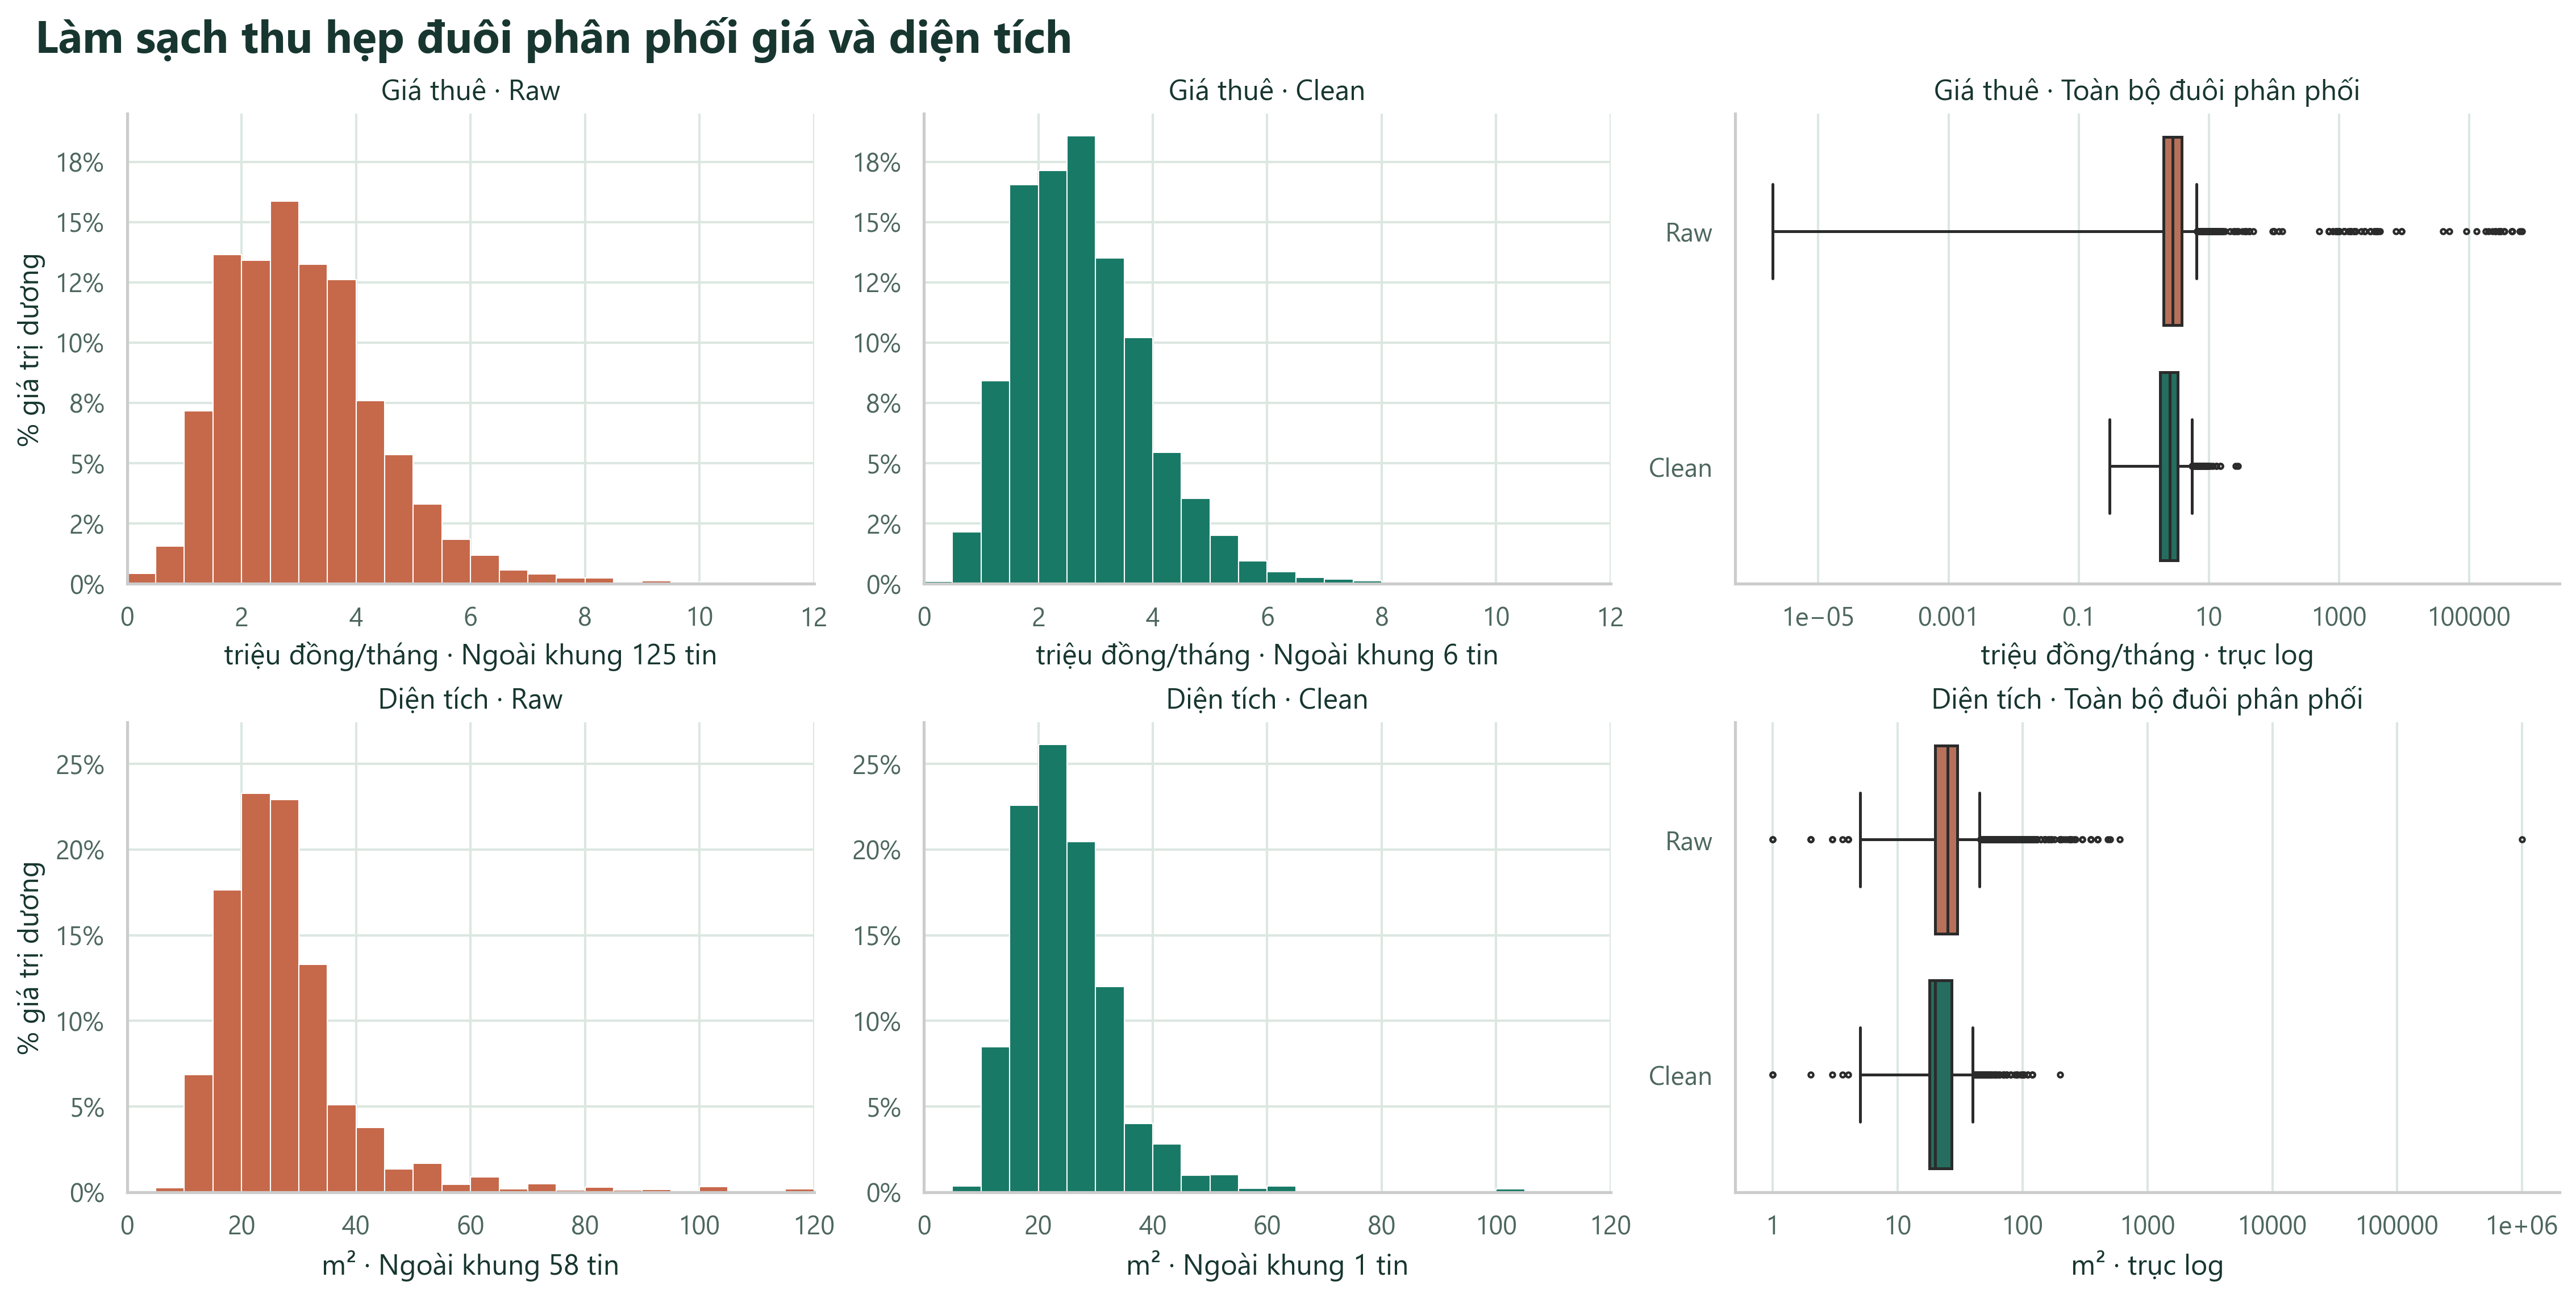

**Điểm nên nói khi trình bày.** Trong Raw có 139 giá ngoài ngưỡng và 23 diện tích trên 200 m². Các giá trị ngoài hai ngưỡng này biến mất trong Clean. Phân phối cũng đổi do tập Clean chỉ giữ phòng trọ và đã xử lý tin trùng. Điểm ngoài râu boxplot là dấu hiệu để kiểm tra, còn tính hợp lệ của từng tin cần dựa vào nội dung và quy tắc nghiệp vụ.

In [3]:
def plot_before_after(raw_numeric, clean_numeric):
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), layout="constrained",
                             gridspec_kw={"width_ratios": [1, 1, 1.2]})
    plot_settings = [
        ("price", "Giá thuê", "triệu đồng/tháng", 1e6, 12, 0.5),
        ("area", "Diện tích", "m²", 1, 120, 5),
    ]
    for row, (column, name, unit, divisor, upper_limit, bin_width) in enumerate(plot_settings):
        datasets = [df[column].loc[df[column].gt(0)].div(divisor) for df in (raw_numeric, clean_numeric)]
        bins = np.arange(0, upper_limit + bin_width / 2, bin_width)
        ymax = 0
        for i, (x, label, color) in enumerate(zip(datasets, ["Raw", "Clean"], [RAW, CLEAN])):
            ax = axes[row, i]
            in_range = x.loc[x.le(upper_limit)]
            # Giữ mẫu số là toàn bộ số dương, kể cả phần ngoài khung histogram.
            ax.hist(in_range, bins=bins, weights=np.full(len(in_range), 100 / len(x)),
                    color=color, edgecolor="white", linewidth=.5)
            ax.set(title=f"{name} · {label}", xlabel=f"{unit} · Ngoài khung {format_number(len(x) - len(in_range))} tin",
                   xlim=(0, upper_limit), ylabel="% giá trị dương" if i == 0 else "")
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
            ymax = max(ymax, ax.get_ylim()[1])
        for ax in axes[row, :2]:
            ax.set_ylim(0, ymax)

        ax = axes[row, 2]
        full_distribution = pd.concat([pd.DataFrame({"Tập": label, "Giá trị": x.to_numpy()})
                            for label, x in zip(["Raw", "Clean"], datasets)], ignore_index=True)
        sns.boxplot(data=full_distribution, x="Giá trị", y="Tập", hue="Tập", order=["Raw", "Clean"],
                    palette={"Raw": RAW, "Clean": CLEAN}, dodge=False, legend=False,
                    fliersize=2, linewidth=1.2, ax=ax)
        # Tính râu IQR ở đơn vị gốc, sau đó mới đổi thang hiển thị.
        ax.set_xscale("log")
        ax.set(title=f"{name} · Toàn bộ đuôi phân phối", xlabel=f"{unit} · trục log", ylabel="")
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
        ax.grid(axis="y", visible=False)
    fig.suptitle("Làm sạch thu hẹp đuôi phân phối giá và diện tích", x=.01, ha="left",
                 fontsize=19, fontweight="bold")
    return fig

plot_before_after(raw_numeric, clean_numeric)
plt.show()

audit_by_group = audit.set_index(["Biến", "Tập"])
display(Markdown(
    f"**Điểm nên nói khi trình bày.** Trong Raw có "
    f"{format_number(audit_by_group.loc[('Giá', 'Raw'), 'Số dương ngoài ngưỡng'])} giá ngoài ngưỡng và "
    f"{format_number(audit_by_group.loc[('Diện tích', 'Raw'), 'Số dương ngoài ngưỡng'])} diện tích trên 200 m². "
    "Các giá trị ngoài hai ngưỡng này biến mất trong Clean. Phân phối cũng đổi do tập Clean chỉ giữ "
    "phòng trọ và đã xử lý tin trùng. Điểm ngoài râu boxplot là dấu hiệu để kiểm tra, "
    "còn tính hợp lệ của từng tin cần dựa vào nội dung và quy tắc nghiệp vụ."
))

### Hồ sơ dữ liệu và đối soát địa danh

Xem 5 dòng Raw, đếm trường trống và thống kê cách xác định quận.

In [4]:
# Dùng các cột minh họa để không hiển thị liên hệ hoặc địa chỉ cụ thể.
display(raw[["source", "price", "area", "posted_date", "detail_status"]].head())
audit_columns = ["title", "description", "price", "area", "address", "posted_date", "phone"]

def count_missing(summary):
    return summary[audit_columns].astype("string").fillna("").apply(
        lambda column: column.str.strip().eq("").sum()
    )

display(pd.DataFrame({"Raw thiếu": count_missing(raw), "Clean thiếu": count_missing(clean)}))
display(clean["district_method"].value_counts().to_frame("Số tin theo cách xác định quận"))
display(Markdown(f"**Vị trí và diện tích sau làm sạch** · "
                 f"{format_number(clean['Quận/Huyện'].eq('Chua_ro').sum())} tin chưa rõ quận/huyện, "
                 f"{format_number(clean['area'].isna().sum())} tin thiếu diện tích."))

,source,price,area,posted_date,detail_status
0,phongtro123.com,3500000,28 m2,"16:22, 25/10/2026",NaN
1,phongtro123.com,3000000,50 m2,27 phút trước,NaN
2,phongtro123.com,3300000,25 m2,15 giờ trước,NaN
3,phongtro123.com,4200000,25 m2,22 giờ trước,NaN
4,phongtro123.com,3400000,30 m2,1 ngày trước,NaN


,Raw thiếu,Clean thiếu
title,0,0
description,17,8
price,0,0
area,0,10
address,0,0
posted_date,0,0
phone,2609,163


,Số tin theo cách xác định quận
district_method,
street_ward_match,2697
breadcrumb,1889
cached_breadcrumb,794
Chua_ro,767
live_breadcrumb,705
text_or_ward,568
official_street_reference,487
address_district,111
official_locality_reference,15


**Vị trí và diện tích sau làm sạch** · 767 tin chưa rõ quận/huyện, 10 tin thiếu diện tích.

### Giá và diện tích

Hai biểu đồ phân tán dùng cùng khung. Pearson được tính trên toàn bộ cặp số đọc được.

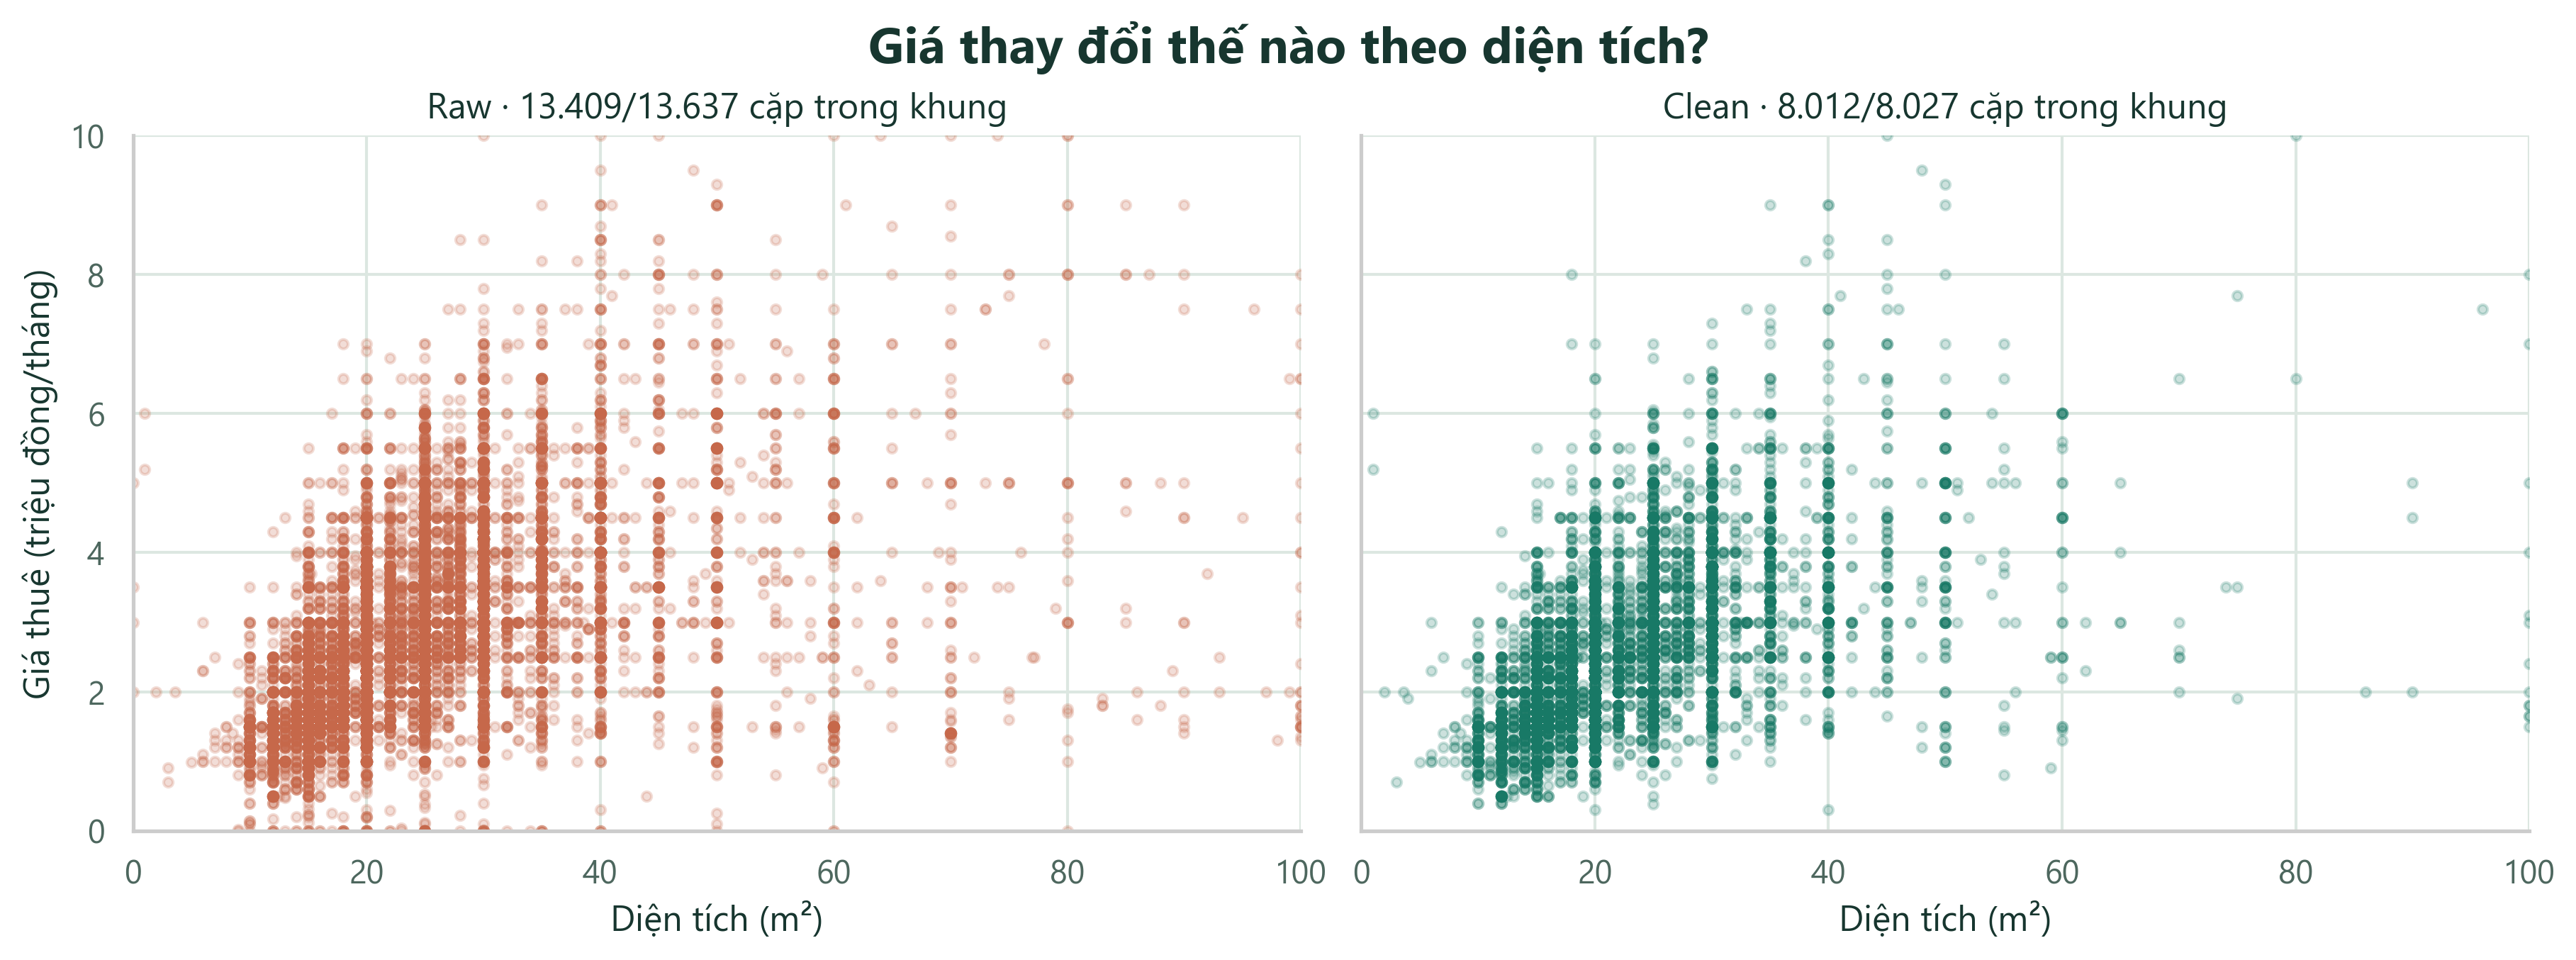

,Pearson giá–diện tích,Độ lệch giá,Độ lệch diện tích
Tập,,,
Raw,-0.000,32.680,119.611
Clean,0.444,3.146,3.336


50% giá ở giữa của Clean nằm trong 1,80–3,30 triệu đồng/tháng. 50% diện tích ở giữa nằm trong 18,0–27,0 m².

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True, layout="constrained")
row = []
for ax, summary, label, color in zip(axes, [raw_numeric, clean_numeric], ["Raw", "Clean"], [RAW, CLEAN]):
    valid_pairs = summary.dropna(subset=["price", "area"])
    displayed_pairs = valid_pairs.loc[valid_pairs["area"].between(0, 100) & valid_pairs["price"].between(0, 10_000_000)]
    ax.scatter(displayed_pairs["area"], displayed_pairs["price"] / 1e6, s=10, alpha=.22, color=color)
    ax.set(title=f"{label} · {format_number(len(displayed_pairs))}/{format_number(len(valid_pairs))} cặp trong khung",
           xlabel="Diện tích (m²)", xlim=(0, 100), ylim=(0, 10))
    row.append({
        "Tập": label, "Pearson giá–diện tích": valid_pairs["price"].corr(valid_pairs["area"]),
        "Độ lệch giá": summary["price"].skew(), "Độ lệch diện tích": summary["area"].skew(),
    })
axes[0].set_ylabel("Giá thuê (triệu đồng/tháng)")
fig.suptitle("Giá thay đổi thế nào theo diện tích?", fontsize=17, fontweight="bold")
plt.show()
display(pd.DataFrame(row).set_index("Tập").round(3))
price_q25, price_q75 = clean_numeric["price"].quantile([.25, .75]) / 1e6
area_q25, area_q75 = clean_numeric["area"].quantile([.25, .75])
display(Markdown(f"50% giá ở giữa của Clean nằm trong {format_number(price_q25, 2)}–{format_number(price_q75, 2)} "
                 f"triệu đồng/tháng. 50% diện tích ở giữa nằm trong {format_number(area_q25, 1)}–"
                 f"{format_number(area_q75, 1)} m²."))

## 2. Tín hiệu giá từ tiện ích trích xuất bằng NLP

Mỗi cặp thanh so sánh **giá thuê trung bình** giữa tin có cờ `1` và tin có cờ `0`. Bảng ghi kèm số tin và chênh lệch trung bình để người xem biết nhóm nào có ít quan sát.

Cờ `0` nghĩa là pipeline **không ghi nhận tiện ích**, gồm cả tin không đề cập. Chênh lệch giá mô tả sự liên hệ trong dữ liệu và có thể đi kèm khác biệt về vị trí, diện tích hoặc nội thất. Muốn đo độ chính xác trích xuất cần đối chiếu với mẫu gán nhãn thủ công.

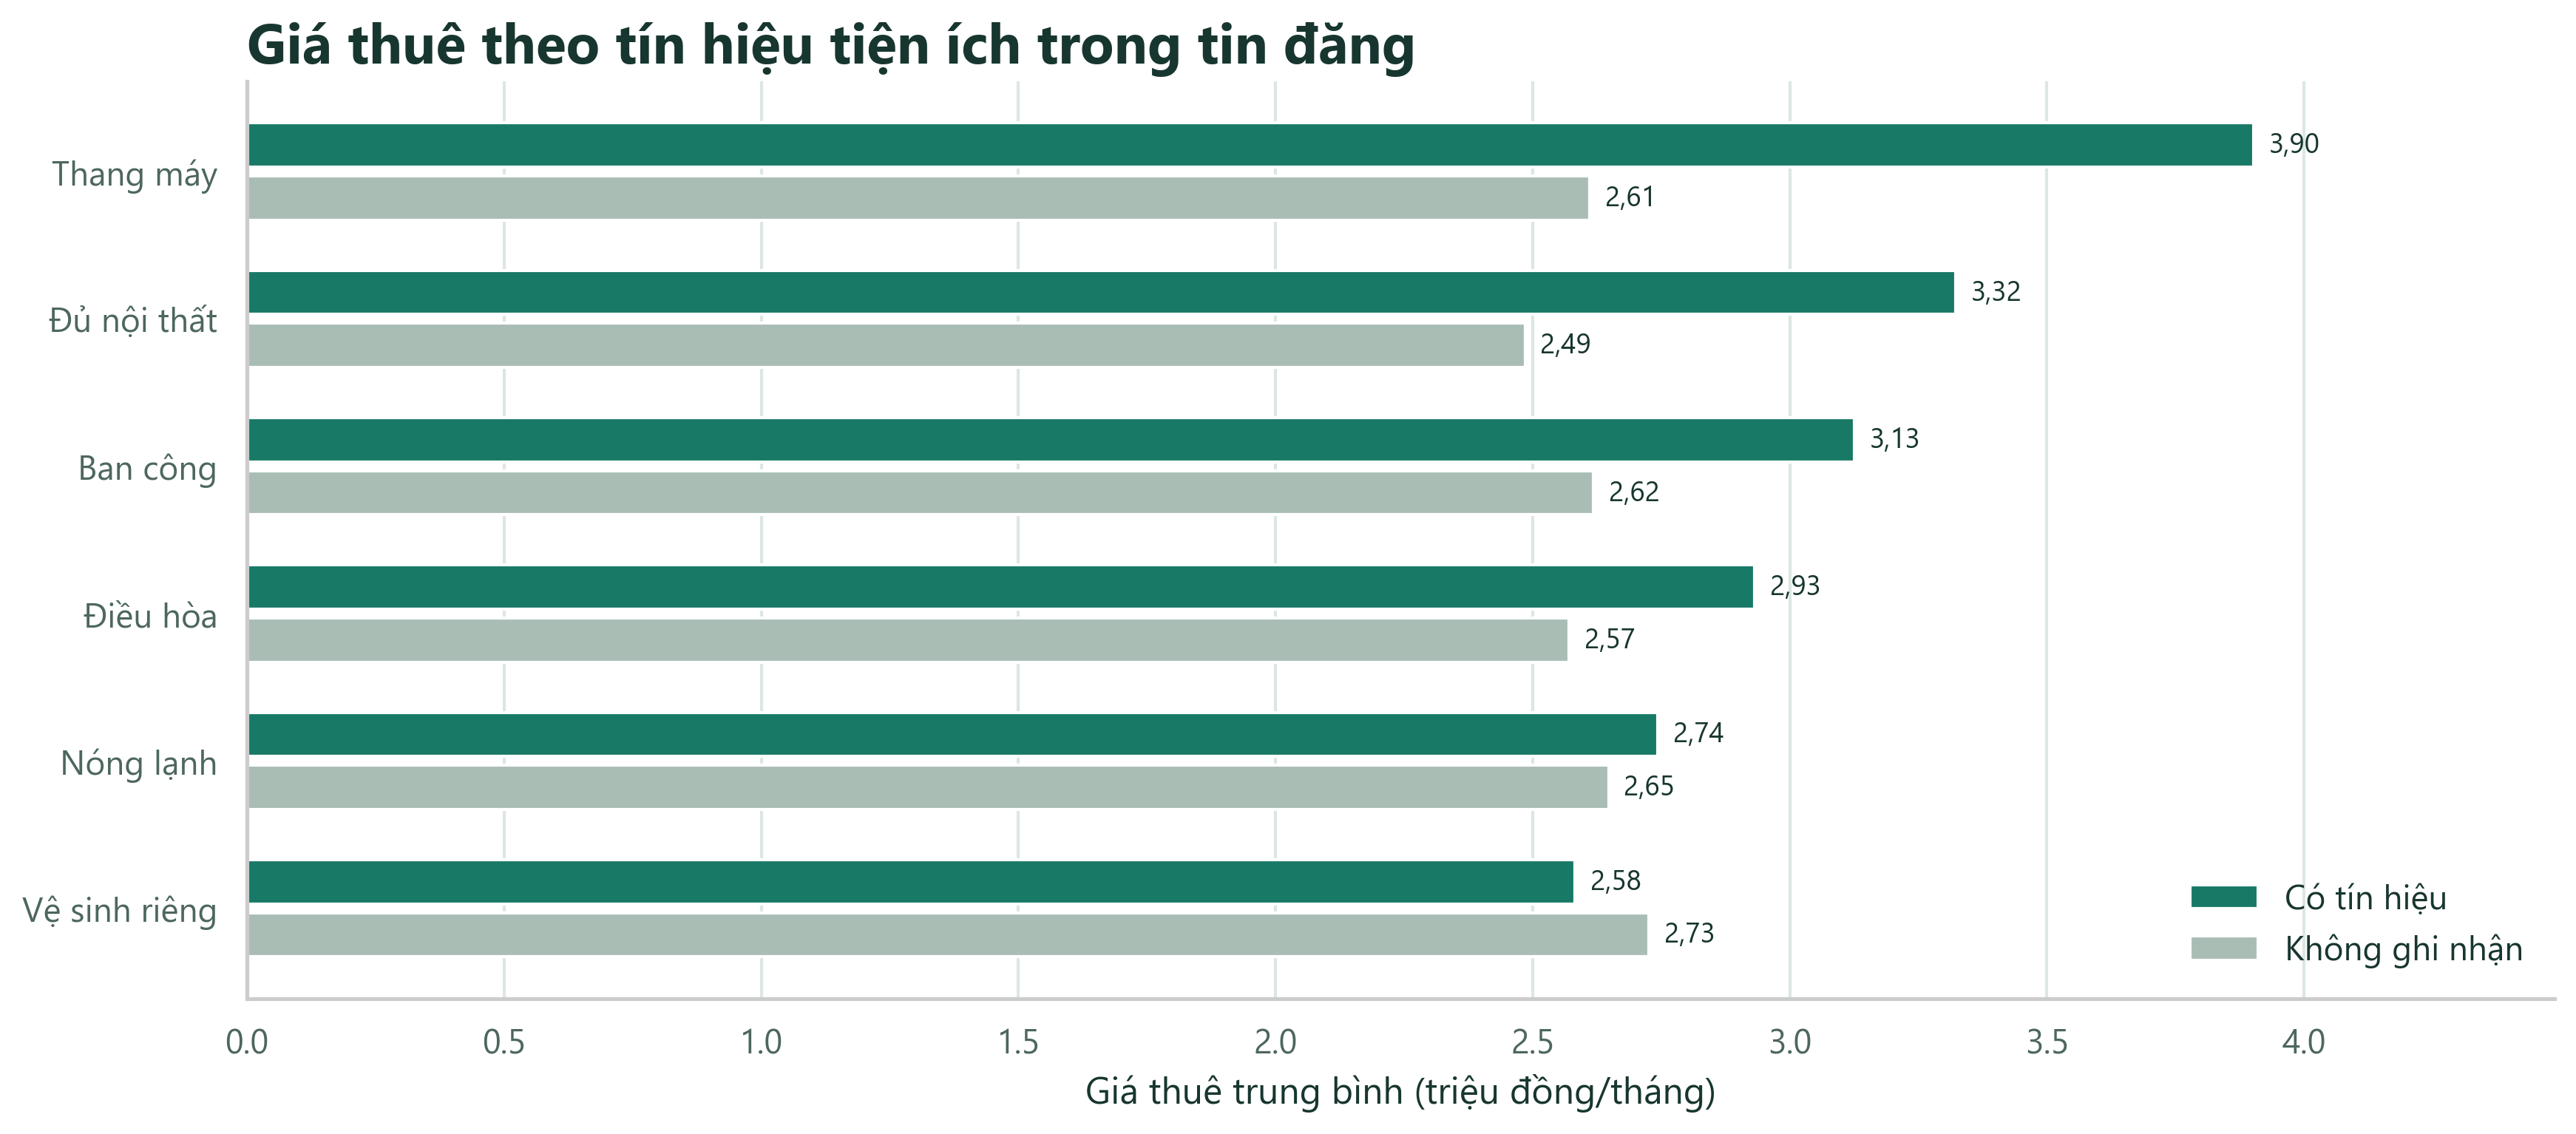

,Số tin có,Số tin không ghi nhận,Có tín hiệu,Không ghi nhận,Chênh lệch
Tiện ích,,,,,
Thang máy,415,7622,3.90,2.61,+1.29
Đủ nội thất,1842,6195,3.32,2.49,+0.84
Ban công,940,7097,3.13,2.62,+0.51
Điều hòa,2364,5673,2.93,2.57,+0.36
Nóng lạnh,2494,5543,2.74,2.65,+0.10
Vệ sinh riêng,2735,5302,2.58,2.73,-0.14


**Tín hiệu nổi bật.** Thang máy có chênh lệch trung bình lớn nhất trong nhóm khảo sát (1,29 triệu đồng/tháng, 415 tin có cờ). Để biết tiện ích cải thiện dự đoán bao nhiêu, có thể so sánh hai mô hình trên cùng tập chia có và không có nhóm đặc trưng này.

In [6]:
ready = pd.read_csv(os.path.join(ROOT, "data", "data_ready.csv"))
AMENITIES = {
    "dieu_hoa": "Điều hòa", "thang_may": "Thang máy", "nong_lanh": "Nóng lạnh",
    "ban_cong": "Ban công", "ve_sinh_khep_kin": "Vệ sinh riêng", "day_du_noi_that": "Đủ nội thất",
}

def summarize_amenities(df):
    rows = []
    for column, name in AMENITIES.items():
        prices_with_amenity = df.loc[df[column].eq(1), "price"].dropna() / 1e6
        prices_without_recorded_amenity = df.loc[df[column].eq(0), "price"].dropna() / 1e6
        rows.append({
            "Tiện ích": name, "Số tin có": len(prices_with_amenity), "Số tin không ghi nhận": len(prices_without_recorded_amenity),
            "Có tín hiệu": prices_with_amenity.mean(), "Không ghi nhận": prices_without_recorded_amenity.mean(),
            "Chênh lệch": prices_with_amenity.mean() - prices_without_recorded_amenity.mean(),
        })
    return pd.DataFrame(rows).sort_values("Chênh lệch", ascending=False).reset_index(drop=True)

def plot_amenities(summary):
    fig, ax = plt.subplots(figsize=(11.5, 5.0), layout="constrained")
    y = np.arange(len(summary))
    for column, delta, color in [("Có tín hiệu", -.18, CLEAN), ("Không ghi nhận", .18, "#A9BDB5")]:
        bars = ax.barh(y + delta, summary[column], height=.30, label=column, color=color)
        ax.bar_label(bars, labels=[format_number(amount, 2) for amount in summary[column]], padding=5, fontsize=9, color=TEXT_COLOR)
    ax.set_yticks(y, labels=summary["Tiện ích"])
    ax.invert_yaxis()
    ax.set_xlim(0, summary[["Có tín hiệu", "Không ghi nhận"]].max().max() * 1.15)
    ax.set_xlabel("Giá thuê trung bình (triệu đồng/tháng)")
    ax.set_title("Giá thuê theo tín hiệu tiện ích trong tin đăng", loc="left", fontsize=18, fontweight="bold")
    ax.legend(loc="lower right", frameon=False)
    ax.grid(axis="y", visible=False)
    return fig

amenity_summary = summarize_amenities(ready)
plot_amenities(amenity_summary)
plt.show()
display(amenity_summary.set_index("Tiện ích").style.format({
    "Có tín hiệu": "{:.2f}", "Không ghi nhận": "{:.2f}", "Chênh lệch": "{:+.2f}",
}))
strongest_signal = amenity_summary.iloc[0]
display(Markdown(
    f"**Tín hiệu nổi bật.** {strongest_signal['Tiện ích']} có chênh lệch trung bình lớn nhất trong nhóm khảo sát "
    f"({format_number(strongest_signal['Chênh lệch'], 2)} triệu đồng/tháng, {format_number(strongest_signal['Số tin có'])} tin có cờ). "
    "Để biết tiện ích cải thiện dự đoán bao nhiêu, có thể so sánh hai mô hình trên cùng tập chia "
    "có và không có nhóm đặc trưng này."
))

## 3. SHAP Summary Plot trên tập test

Tập test được tái lập theo quy tắc trong `train_model.py`. CatBoost tính SHAP sau bước tiền xử lý đã fit. Nếu một địa danh đi vào mô hình dưới dạng danh mục và qua target encoding, đóng góp của hai biểu diễn được cộng về cùng đặc trưng gốc trước khi xếp hạng.

- **Biểu đồ thanh** xếp hạng theo trung bình `|SHAP|` trên tập test.
- **Beeswarm** cho biết hướng và độ lớn của đóng góp trên từng tin. Điểm bên phải mốc 0 làm giá dự đoán tăng so với mức gốc, điểm bên trái làm giá giảm. Các điểm dùng cùng màu để đọc hướng đóng góp mà không ngụ ý địa danh có thứ tự thấp–cao.

In [7]:
def get_test_set(df):
    dates = pd.to_datetime(df["posted_date"], utc=True).dt.tz_convert("Asia/Ho_Chi_Minh")
    chronological_order = dates.sort_values(kind="stable").index
    sorted_data = df.loc[chronological_order].copy()
    sorted_data["ngay"] = dates.loc[chronological_order]
    test_cutoff = sorted_data["ngay"].dt.normalize().iloc[int(len(sorted_data) * .80)]
    return sorted_data.loc[sorted_data["ngay"].ge(test_cutoff)], test_cutoff

def compute_shap(model, test):
    x = test.loc[:, model.feature_names_in_]
    preprocessor = model.named_steps["columntransformer"]
    catboost = model.named_steps["catboostregressor"]
    pool = Pool(
        preprocessor.transform(x), cat_features=catboost.get_cat_feature_indices(),
        text_features=catboost.get_text_feature_indices(),
    )
    shap_values = catboost.get_feature_importance(data=pool, type="ShapValues", thread_count=2)
    original_feature_names = [name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()]
    contributions = pd.DataFrame(shap_values[:, :-1]).T.groupby(original_feature_names, sort=False).sum().T
    base_values = shap_values[:, -1]
    # Kiểm tra đóng góp sau khi gộp vẫn khôi phục được giá dự đoán.
    np.testing.assert_allclose(base_values + contributions.sum(axis=1), model.predict(x), atol=1e-4, rtol=0)
    return contributions / 1e6, base_values / 1e6

test, test_cutoff = get_test_set(ready)
model = joblib.load(os.path.join(ROOT, "models", "best_model.pkl"))
contributions, base_values = compute_shap(model, test)
display(Markdown(f"**Tập test** · {format_number(len(test))} tin, từ "
                 f"{test_cutoff:%d/%m/%Y} đến {test['ngay'].max():%d/%m/%Y}. "
                 "Tổng đóng góp SHAP cộng mức gốc đã được đối chiếu với giá dự đoán trên toàn bộ tập."))

**Tập test** · 1.618 tin, từ 02/01/2026 đến 02/11/2026. Tổng đóng góp SHAP cộng mức gốc đã được đối chiếu với giá dự đoán trên toàn bộ tập.

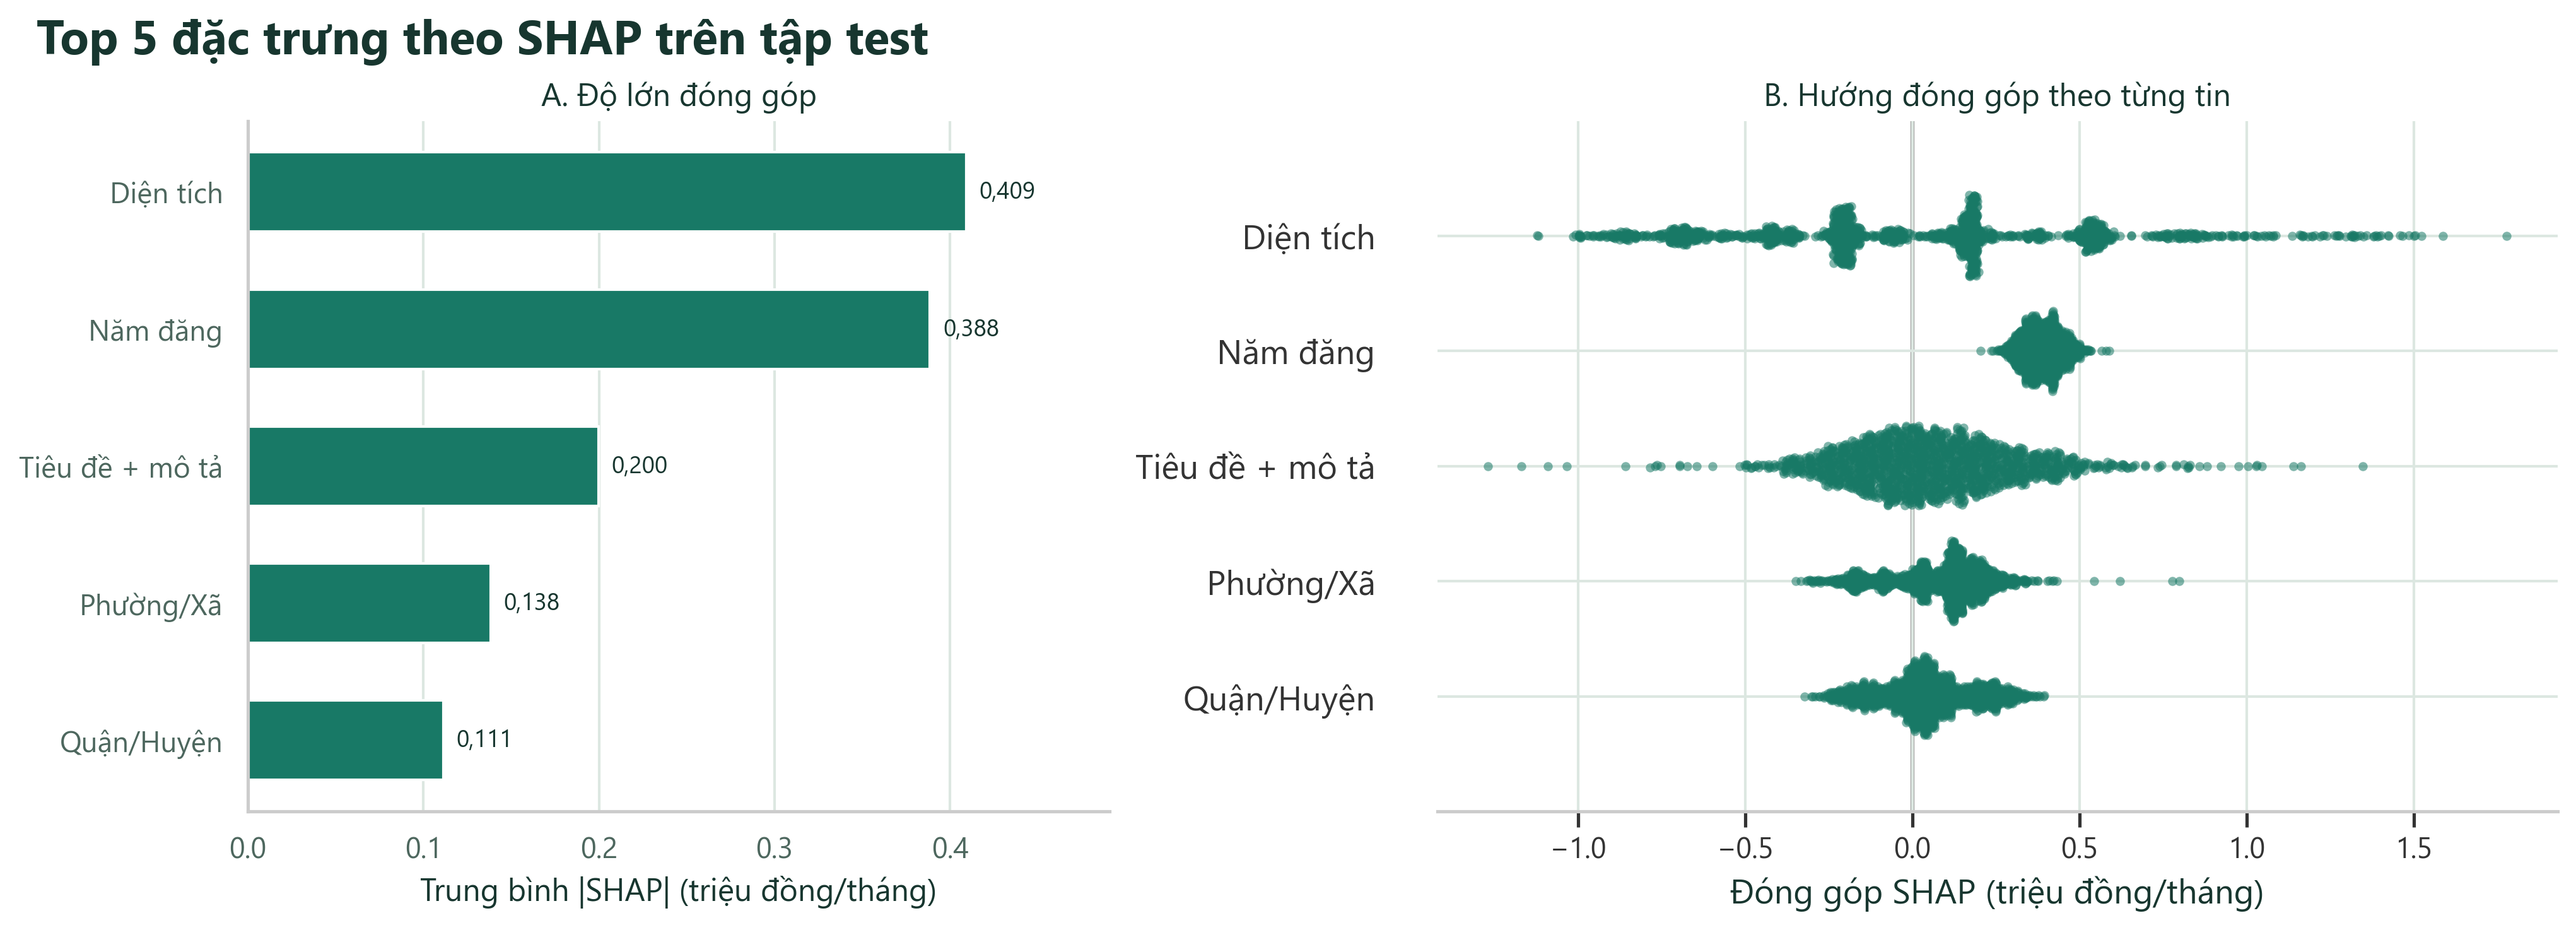

,Trung bình |SHAP| (triệu đồng/tháng)
Diện tích,0.409
Năm đăng,0.388
Tiêu đề + mô tả,0.200
Phường/Xã,0.138
Quận/Huyện,0.111


**Kết luận cho phần trình bày.** Năm đặc trưng đứng đầu là Diện tích, Năm đăng, Tiêu đề + mô tả, Phường/Xã, Quận/Huyện. Đây là các đặc trưng mô hình sử dụng mạnh nhất trên tập test đang xét. Dấu SHAP giải thích dự đoán của từng tin, nên một đặc trưng có thể làm tăng hoặc giảm giá ở các tin khác nhau.

In [8]:
FEATURE_LABELS = {
    **AMENITIES, "text": "Tiêu đề + mô tả", "area": "Diện tích", "area_was_missing": "Thiếu diện tích",
    "posted_year": "Năm đăng", "posted_month": "Tháng đăng", "chung_chu": "Chung chủ",
    "rieng_chu": "Không chung chủ", "moi_xay": "Mới xây", "cua_so": "Cửa sổ",
}

def plot_shap(contributions, base_values):
    top = contributions.abs().mean().nlargest(5)
    label = [FEATURE_LABELS.get(name, name) for name in top.index]
    fig, (ax_bar, ax_swarm) = plt.subplots(1, 2, figsize=(13.5, 4.8), layout="constrained",
                                          gridspec_kw={"width_ratios": [1, 1.3]})
    bars = ax_bar.barh(label[::-1], top.to_numpy()[::-1], color=CLEAN, height=.58)
    ax_bar.bar_label(bars, labels=[format_number(amount, 3) for amount in top[::-1]], padding=5, fontsize=9, color=TEXT_COLOR)
    ax_bar.set_xlim(0, top.max() * 1.2)
    ax_bar.set(xlabel="Trung bình |SHAP| (triệu đồng/tháng)", title="A. Độ lớn đóng góp")
    ax_bar.grid(axis="y", visible=False)

    explanation = shap.Explanation(
        values=contributions.loc[:, top.index].to_numpy(), base_values=base_values, feature_names=label,
    )
    shap.plots.beeswarm(explanation, max_display=5, group_remaining_features=False,
                        color=CLEAN, color_bar=False, alpha=.55, s=12, ax=ax_swarm,
                        plot_size=None, show=False)
    ax_swarm.set(xlabel="Đóng góp SHAP (triệu đồng/tháng)", title="B. Hướng đóng góp theo từng tin")
    fig.suptitle("Top 5 đặc trưng theo SHAP trên tập test", x=.01, ha="left", fontsize=18, fontweight="bold")
    return fig, pd.Series(top.to_numpy(), index=label, name="Trung bình |SHAP| (triệu đồng/tháng)")

fig, shap_ranking = plot_shap(contributions, base_values)
plt.show()
display(shap_ranking.round(3).to_frame())
display(Markdown("**Kết luận cho phần trình bày.** Năm đặc trưng đứng đầu là "
                 + ", ".join(shap_ranking.index) + ". Đây là các đặc trưng mô hình sử dụng mạnh nhất "
                 "trên tập test đang xét. Dấu SHAP giải thích dự đoán của từng tin, "
                 "nên một đặc trưng có thể làm tăng hoặc giảm giá ở các tin khác nhau."))